# Numerical simulation for `Double-bracket quantum algorithms for quantum imaginary-time evolution`

# v3.5: variable s optimization (optimize for k=1 then k=2) but optimize 2 parameter at once

# 1. Initialization

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import expm

import sys
sys.path.append('..')
from functions.qite_gci import *

plt.rcParams['axes.labelsize'] = 16
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['font.size'] = 16
plt.rcParams['savefig.dpi'] = 75
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['lines.markersize'] = 8
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['legend.labelspacing'] = .3
plt.rcParams['legend.columnspacing']= .3
plt.rcParams['legend.handletextpad']= .1
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = "serif"
plt.rcParams['font.serif'] = "cm"
plt.rcParams["figure.figsize"] = [5, 3.50]
plt.rcParams["figure.autolayout"] = True


In [2]:
L = 1
H_sh = hamiltonians.SymbolicHamiltonian(Z(0), nqubits = 1)
H = - H_sh.matrix
eigs = H_sh.eigenvalues()
target_energy = min(eigs)

[Qibo 0.2.12|ERROR|2025-03-11 01:04:38]: The 'qibojit' backends' provider is not available. Check that a Python package named 'qibojit' is installed, and it is exposing valid Qibo backends.
[Qibo 0.2.12|ERROR|2025-03-11 01:04:38]: The 'qibojit' backends' provider is not available. Check that a Python package named 'qibojit' is installed, and it is exposing valid Qibo backends.
[Qibo 0.2.12|INFO|2025-03-11 01:04:38]: Using numpy backend on /CPU:0
[Qibo 0.2.12|WARNING|2025-03-11 01:04:38]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.


In [3]:
psi0 = np.random.rand(2)
psi0 /= np.linalg.norm(psi0)
psi0 = psi0[np.newaxis].T

# 3. Run DB-QITE with DME

[Qibo 0.2.12|WARNING|2025-03-11 01:04:38]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
c:\Python\Lib\site-packages\matplotlib\cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Python\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


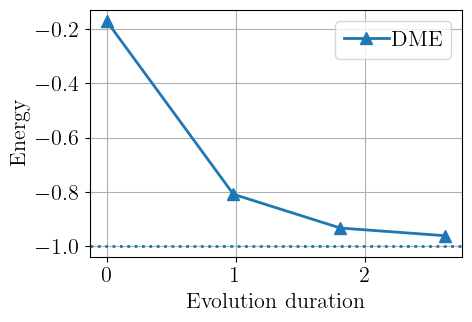

In [4]:
def DME(instruction,data,t,M=100): 
    _t = t/M 
    c = np.cos(_t)
    s = np.sin(_t)
    for i in range(M): 
        data = c**2 * data + s**2 * instruction + 1j * s * c * (instruction @ data - data @ instruction)
        # print(data)
    return data

def QITE_GCI_dme(psi, s, M=100):
    QITE_GCI_dme.label=r"DME"
    QITE_GCI_dme.marker = '^'
    PSI = psi@psi.T.conj()
    U_t = expm(1j*s*H)
    state = DME( U_t @ PSI @ U_t.conj().T, PSI, s, M = M)
    return state

def QITE_dme_select_M(M=100):
    def QITE_GCI_dme(psi, s, M=M):
        QITE_GCI_dme.label=r"DME"
        QITE_GCI_dme.marker = '^'
        PSI = psi@psi.T.conj()
        U_t = expm(1j*s*H)
        state = DME( U_t @ PSI @ U_t.conj().T, PSI, s, M = M)
        return state
    return QITE_GCI_dme

RGCI_dme = GCI(QITE_dme_select_M(), psi0, None, [0.99,0.91,0.9])
results_RGCI_dme = RGCI_dme.execute_gci()
RGCI_dme.plot_GCI_results(results_RGCI_dme)

## 3.2 Define an identity operation

In [5]:
def initial_psi(psi, s):
    initial_psi.label="Initial state"
    initial_psi.marker = 'o'
    return psi


In [6]:
def max_excitation(thetas, fidelity, target_fidelity, tolerance=1e-2):
    """
    Find the x value corresponding to y = y_const within a given tolerance.
    """
    return next((xi for xi, yi in zip(thetas, fidelity) if abs(yi - target_fidelity) <= tolerance), None)

In [7]:
from scipy.optimize import minimize

## 3.3 k=1

In [8]:
optimal_s_for_M_k1 = []
Ms = [1,2,3,100]
# s_list = []
k = 1
for M in Ms:
    psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
    def dbqite(s):
        return GCI(QITE_dme_select_M(M), psi0, None, [s]).execute_gci()[0][-1].real

    init_guess = 0.6
    result = minimize(dbqite, init_guess, method='BFGS')

    optimal_s = result.x[0]
    min_output = result.fun

    print(f"Optimal s for M = {M}, k = {k}: s = {np.round(optimal_s,2)}, phi = {np.round(np.sqrt(optimal_s),2)}")
    optimal_s_for_M_k1.append((M,optimal_s))
    print(f't = {np.round(np.sqrt(optimal_s)/(2*np.pi*M),4)} tau')
    # s_list.append(optimal_s)
print(optimal_s_for_M_k1)

[Qibo 0.2.12|WARNING|2025-03-11 01:04:38]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:38]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:38]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:38]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:38]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:38]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:38]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:38]: Calculating 

Optimal s for M = 1, k = 1: s = 0.79, phi = 0.89
t = 0.141 tau
Optimal s for M = 2, k = 1: s = 0.88, phi = 0.94
t = 0.0745 tau
Optimal s for M = 3, k = 1: s = 0.9, phi = 0.95
t = 0.0504 tau
Optimal s for M = 100, k = 1: s = 0.95, phi = 0.98
t = 0.0016 tau
[(1, 0.785398159105983), (2, 0.8757927102818437), (3, 0.9028328752721863), (100, 0.953726038542698)]


In [9]:
psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
psi0 = np.array([[0],[1]])
psis = []
number_steps = 100
thetas = np.linspace(0,1,number_steps)
sigma_x_np = np.array([[0,1],
                       [1,0]])
for i in thetas:
    psis.append(expm(-1j*np.pi/2*sigma_x_np*i) @ psi0)
psis = np.asarray(psis)


res_init = []
dict_res_DBQITE = {}

for psi0 in psis:
    res_init.append(GCI(initial_psi, psi0, 1, np.linspace(0.01,1,2)).execute_gci()[0][-1])   

target_fidelity = 0.9
for M,s in optimal_s_for_M_k1:
    print(M,s)
    res_DBQITE = []
    for psi0 in psis:
        res_DBQITE.append(GCI(QITE_dme_select_M(M), psi0, None, [s]*k).execute_gci()[0][-1])
        # dict_res_DBQITE.update({f'M={np.round(M,2)}, s={np.round(s,2):.2f}' : res_DBQITE})
        dict_res_DBQITE.update({f'M={np.round(M,2)}' : res_DBQITE})

print(f'k={k}')

[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating 

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:39]: Calculating 

100 0.953726038542698
k=1


In [10]:
dict_fid_RGCI = {key: [(1-E)/2 for E in values] for key, values in dict_res_DBQITE.items()}

(1, 0.68)
(2, 0.62)
(3, 0.6)
(100, 0.52)


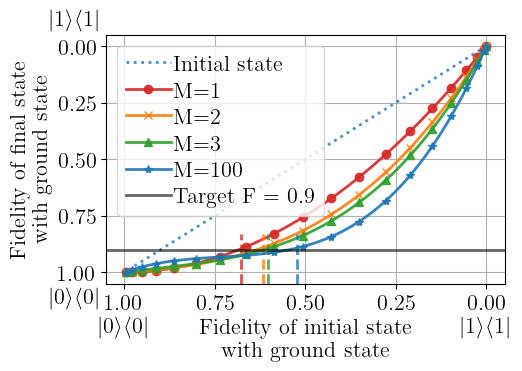

In [11]:
state_0 = np.array([1, 0], dtype=complex)
def fidelity_with_0(state):
    shape = np.shape(state)
    if shape[0] == shape[1]:
        return np.real(np.conj(state_0).T @ state @ state_0)
    else:
        dm = state@state.T.conj()
        return np.real(np.conj(state_0).T @ dm @ state_0)
    
fidelities_original = [fidelity_with_0(x) for x in psis]

from matplotlib import cm
# color = cm.rainbow(np.linspace(1, 0, len(Ms)))
color = ['C3','C1','C2','C0']

max_ext_list = []
fig, ax =  plt.subplots(figsize=(5.5,4))
# ax.plot(np.linspace(0,1,number_steps),res_ITE,label=r"$ITE |{\Psi(\tau)}\rangle$",marker="^")
# ax.plot(np.linspace(0,1,number_steps),res_DBI,label=r"$DBI |{\sigma_k}\rangle$",marker='o')
fidelity = [(1-E)/2 for E in res_init]
ax.plot(fidelities_original,fidelity,label=r"Initial state",linestyle=':', alpha=0.8)
i=0

markers = ['o','x','^','*','P','*','h']

for key,value in dict_fid_RGCI.items():
    max_ext = max_excitation(fidelities_original,np.real(value),target_fidelity)
    if max_ext is not None:
        ax.axvline(x=max_ext,ymax=0.2, color=color[i], alpha=0.8,linestyle='--')
        max_ext_list.append(max_ext)

    ax.plot(fidelities_original,value,label=key,color=color[i],marker=markers[i],markevery=5,markersize=6,alpha=0.9)
    i+=1


plt.gca().invert_xaxis()
plt.gca().invert_yaxis()


# plt.title(r"$k = $" + f" {k}\n")
plt.ylabel('Fidelity of final state\nwith ground state')
plt.xlabel('Fidelity of initial state\nwith ground state')
ax.axhline(y=target_fidelity, color='k', alpha=0.6,label=r'Target F = 'f'{target_fidelity}')
# ax.legend(bbox_to_anchor=(1.05, 1))
if k==1:
        ax.legend()
ax.grid()


_off_set = 0.13

y_min, y_max = ax.get_ylim()
ax.text(0, y_min - _off_set * (y_max - y_min),r'$|1\rangle\langle 1|$', 
        ha='center', va='top')
ax.text(1, y_min - _off_set * (y_max - y_min), r'$|0\rangle\langle 0|$', 
        ha='center', va='top')

# x_min, x_max = ax.get_xlim()
# ax.text(x_min - _off_set * (x_max - x_min), 0, r'$|1\rangle\langle 1|$', 
#         ha='right', va='center')
# ax.text(x_min - _off_set * (x_max - x_min), 1, r'$|0\rangle\langle 0|$', 
#         ha='right', va='center')

x_min, x_max = ax.get_xlim()
        
# Add text labels below y=0 and above y=1
ax.text(1 + _off_set*0.5, 0 + _off_set*0.8 * (ax.get_ylim()[1] - ax.get_ylim()[0]), r'$|1\rangle\langle 1|$', 
        ha='right', va='center')
ax.text(1 + _off_set*0.5, 1 - _off_set*0.8 * (ax.get_ylim()[1] - ax.get_ylim()[0]), r'$|0\rangle\langle 0|$', 
        ha='right', va='center')

plt.savefig(f'plots/QITE_DME_k_{k}_M_fidelity_final_vs_original.pdf')

plt.tight_layout()

for M, max_val in zip(Ms, max_ext_list):
    print((M,np.round(max_val,2)))



## 3.4 k=2

In [12]:
psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
psis = []
number_steps = 50
for i in np.linspace(0,1,number_steps):
    psis.append(expm(-1j*np.pi/2*sigma_x_np*i) @ psi0)
psis = np.asarray(psis)

times_ITE = np.linspace(0.04,0.7,100).tolist()
res_ITE = []
res_DBI = []
res_init = []
dict_res_RHOPF = {}

num_s = 15
for s in np.linspace(0.01,1,num_s):
    res_RGCI = []
    for psi0 in psis:
        res_RGCI.append(GCI(QITE_dme_select_M(M=2), psi0, None, [s]).execute_gci()[0][-1])
        dict_res_RHOPF.update({r"$|{\omega_k}\rangle$" +f' for s={np.round(s,2)}' : res_RGCI})

[Qibo 0.2.12|WARNING|2025-03-11 01:04:40]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:40]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:40]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:40]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:40]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:40]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:40]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:40]: Calculating 

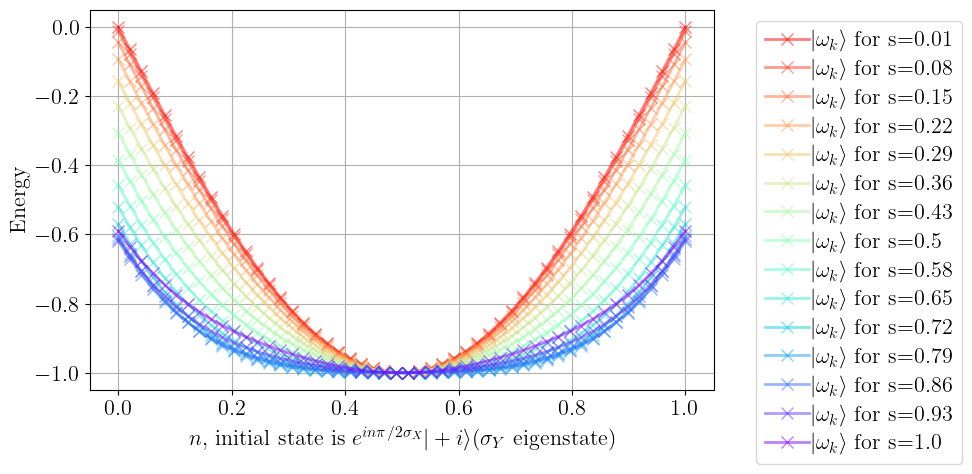

In [13]:
from matplotlib import cm
color = cm.rainbow(np.linspace(1, 0, num_s))

plt.figure(figsize=(10,5))
# plt.plot(np.linspace(0,1,number_steps),res_ITE,label=r"$ITE |{\Psi(\tau)}\rangle$",marker="^")
# plt.plot(np.linspace(0,1,number_steps),res_DBI,label=r"$DBI |{\sigma_k}\rangle$",marker='o')
# plt.plot(np.linspace(0,1,number_steps),res_init,label=r"Initial state",marker='d')
i=0
for key,value in dict_res_RHOPF.items():
    plt.plot(np.linspace(0,1,number_steps),value,label=key,marker='x',color=color[i],alpha=0.5)
    i+=1
# plt.title(f'QITE RHOPF after {qite_step} steps')
plt.ylabel('Energy')
plt.xlabel(r'$n$, initial state is $e^{i n\pi/2 \sigma_X} |+i\rangle (\sigma_Y$ eigenstate)')
plt.legend(bbox_to_anchor=(1.05, 1))
plt.grid()
# plt.savefig(f'QITE_higher_order_{qite_step}_steps.pdf')

In [14]:
optimal_s_for_M_k2 = []
Ms = [1,2,3,100]
# s_list = []
k = 2
for i, M in enumerate(Ms):
    psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
    def dbqite(s):
        
        return GCI(QITE_dme_select_M(M), psi0, None, [optimal_s_for_M_k1[i][1] ,s]).execute_gci()[0][-1].real
    # print(optimal_s_for_M_k1[i][1])

    init_guess = 0.71
    result = minimize(dbqite, init_guess, method='BFGS')

    optimal_s = result.x[0]
    min_output = result.fun

    print(f"Optimal s for M = {M}, k = {k}: s = {np.round(optimal_s,2)}, phi = {np.round(np.sqrt(optimal_s),2)}")
    optimal_s_for_M_k2.append((M,[optimal_s_for_M_k1[i][1],optimal_s]))
    print(f't = {np.round(np.sqrt(optimal_s)/(2*np.pi*M),4)} tau')
    # s_list.append(optimal_s)
print(optimal_s_for_M_k2)

[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating 

Optimal s for M = 1, k = 2: s = 0.79, phi = 0.89
t = 0.141 tau
Optimal s for M = 2, k = 2: s = 0.8, phi = 0.89
t = 0.071 tau
Optimal s for M = 3, k = 2: s = 0.79, phi = 0.89
t = 0.047 tau
Optimal s for M = 100, k = 2: s = 0.74, phi = 0.86
t = 0.0014 tau
[(1, [0.785398159105983, 0.7853986722291612]), (2, [0.8757927102818437, 0.7953183070496507]), (3, [0.9028328752721863, 0.7855867939043]), (100, [0.953726038542698, 0.7395487449273491])]


In [15]:
psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
psi0 = np.array([[0],[1]])
psis = []
number_steps = 100
thetas = np.linspace(0,1,number_steps)
sigma_x_np = np.array([[0,1],
                       [1,0]])
for i in thetas:
    psis.append(expm(-1j*np.pi/2*sigma_x_np*i) @ psi0)
psis = np.asarray(psis)


res_init = []
dict_res_DBQITE = {}

for psi0 in psis:
    res_init.append(GCI(initial_psi, psi0, 1, np.linspace(0.01,1,2)).execute_gci()[0][-1])   

target_fidelity = 0.9
for M,s in optimal_s_for_M_k2:
    print(M,s)
    res_DBQITE = []
    for psi0 in psis:
        res_DBQITE.append(GCI(QITE_dme_select_M(M), psi0, None, s).execute_gci()[0][-1])
        # dict_res_DBQITE.update({f'M={np.round(M,2)}, s={np.round(s,2):.2f}' : res_DBQITE})
        dict_res_DBQITE.update({f'M={np.round(M,2)}' : res_DBQITE})

print(f'k={k}')

[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating 

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating 

2 [0.8757927102818437, 0.7953183070496507]
3 [0.9028328752721863, 0.7855867939043]


[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating 

100 [0.953726038542698, 0.7395487449273491]


[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating 

k=2


In [16]:
dict_fid_RGCI = {key: [(1-E)/2 for E in values] for key, values in dict_res_DBQITE.items()}

(1, 0.54)
(2, 0.51)
(3, 0.43)
(100, 0.22)


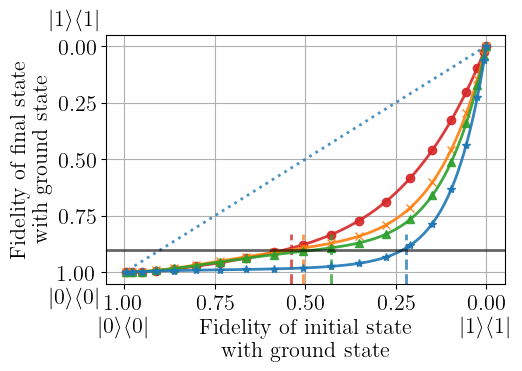

In [17]:
fidelities_original = [fidelity_with_0(x) for x in psis]

from matplotlib import cm
# color = cm.rainbow(np.linspace(1, 0, len(Ms)))
color = ['C3','C1','C2','C0']

max_ext_list = []
fig, ax =  plt.subplots(figsize=(5.5,4))
# ax.plot(np.linspace(0,1,number_steps),res_ITE,label=r"$ITE |{\Psi(\tau)}\rangle$",marker="^")
# ax.plot(np.linspace(0,1,number_steps),res_DBI,label=r"$DBI |{\sigma_k}\rangle$",marker='o')
fidelity = [(1-E)/2 for E in res_init]
ax.plot(fidelities_original,fidelity,label=r"Initial state",linestyle=':', alpha=0.8)
i=0

markers = ['o','x','^','*','P','*','h']

for key,value in dict_fid_RGCI.items():
    max_ext = max_excitation(fidelities_original,np.real(value),target_fidelity)
    if max_ext is not None:
        ax.axvline(x=max_ext,ymax=0.2, color=color[i], alpha=0.8,linestyle='--')
        max_ext_list.append(max_ext)

    ax.plot(fidelities_original,value,label=key,color=color[i],marker=markers[i],markevery=5,markersize=6,alpha=0.9)
    i+=1


plt.gca().invert_xaxis()
plt.gca().invert_yaxis()


# plt.title(r"$k = $" + f" {k}\n")
plt.ylabel('Fidelity of final state\nwith ground state')
plt.xlabel('Fidelity of initial state\nwith ground state')
ax.axhline(y=target_fidelity, color='k', alpha=0.6,label=r'Target F = 'f'{target_fidelity}')
# ax.legend(bbox_to_anchor=(1.05, 1))
if k==1:
        ax.legend()
ax.grid()


_off_set = 0.13

y_min, y_max = ax.get_ylim()
ax.text(0, y_min - _off_set * (y_max - y_min),r'$|1\rangle\langle 1|$', 
        ha='center', va='top')
ax.text(1, y_min - _off_set * (y_max - y_min), r'$|0\rangle\langle 0|$', 
        ha='center', va='top')

# x_min, x_max = ax.get_xlim()
# ax.text(x_min - _off_set * (x_max - x_min), 0, r'$|1\rangle\langle 1|$', 
#         ha='right', va='center')
# ax.text(x_min - _off_set * (x_max - x_min), 1, r'$|0\rangle\langle 0|$', 
#         ha='right', va='center')

x_min, x_max = ax.get_xlim()
        
# Add text labels below y=0 and above y=1
ax.text(1 + _off_set*0.5, 0 + _off_set*0.8 * (ax.get_ylim()[1] - ax.get_ylim()[0]), r'$|1\rangle\langle 1|$', 
        ha='right', va='center')
ax.text(1 + _off_set*0.5, 1 - _off_set*0.8 * (ax.get_ylim()[1] - ax.get_ylim()[0]), r'$|0\rangle\langle 0|$', 
        ha='right', va='center')

plt.savefig(f'plots/QITE_DME_k_{k}_M_fidelity_final_vs_original.pdf')

plt.tight_layout()

for M, max_val in zip(Ms, max_ext_list):
    print((M,np.round(max_val,2)))



## 3.5 k=3

In [18]:
optimal_s_for_M_k3 = []
# Ms = [1,2,100]
# s_list = []
k = 3
for i, M in enumerate(Ms):
    psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
    def dbqite(s):
        return GCI(QITE_dme_select_M(M), psi0, None, optimal_s_for_M_k2[i][1] + [s]).execute_gci()[0][-1].real

    init_guess = 0.8
    result = minimize(dbqite, init_guess, method='BFGS')

    optimal_s = result.x[0]
    min_output = result.fun

    print(f"Optimal s for M = {M}, k = {k}: s = {np.round(optimal_s,2)}, phi = {np.round(np.sqrt(optimal_s),2)}")
    optimal_s_for_M_k3.append((M,optimal_s_for_M_k2[i][1] + [optimal_s]))
    print(f't = {np.round(np.sqrt(optimal_s)/(2*np.pi*M),4)} tau')
    # s_list.append(optimal_s)
print(optimal_s_for_M_k3)

[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating 

Optimal s for M = 1, k = 3: s = 0.79, phi = 0.89
t = 0.141 tau
Optimal s for M = 2, k = 3: s = 0.79, phi = 0.89
t = 0.0707 tau
Optimal s for M = 3, k = 3: s = 0.78, phi = 0.88
t = 0.0469 tau
Optimal s for M = 100, k = 3: s = 0.71, phi = 0.84
t = 0.0013 tau
[(1, [0.785398159105983, 0.7853986722291612, 0.7853951538529089]), (2, [0.8757927102818437, 0.7953183070496507, 0.7904218544089816]), (3, [0.9028328752721863, 0.7855867939043, 0.7829750620203967]), (100, [0.953726038542698, 0.7395487449273491, 0.7057614425000356])]


In [19]:
psi0 = np.sqrt(1/2)*np.array([[1],[1j]])
psi0 = np.array([[0],[1]])
psis = []
number_steps = 100
thetas = np.linspace(0,1,number_steps)
sigma_x_np = np.array([[0,1],
                       [1,0]])
for i in thetas:
    psis.append(expm(-1j*np.pi/2*sigma_x_np*i) @ psi0)
psis = np.asarray(psis)


res_init = []
dict_res_DBQITE = {}

for psi0 in psis:
    res_init.append(GCI(initial_psi, psi0, 1, np.linspace(0.01,1,2)).execute_gci()[0][-1])   

target_fidelity = 0.9
for M,s in optimal_s_for_M_k3:
    print(M,s)
    res_DBQITE = []
    for psi0 in psis:
        res_DBQITE.append(GCI(QITE_dme_select_M(M), psi0, None, s).execute_gci()[0][-1])
        # dict_res_DBQITE.update({f'M={np.round(M,2)}, s={np.round(s,2):.2f}' : res_DBQITE})
        dict_res_DBQITE.update({f'M={np.round(M,2)}' : res_DBQITE})

print(f'k={k}')

[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:41]: Calculating 

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating 

2 [0.8757927102818437, 0.7953183070496507, 0.7904218544089816]
3 [0.9028328752721863, 0.7855867939043, 0.7829750620203967]


[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating 

100 [0.953726038542698, 0.7395487449273491, 0.7057614425000356]


[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating the dense form of a symbolic Hamiltonian. This operation is memory inefficient.
[Qibo 0.2.12|WARNING|2025-03-11 01:04:42]: Calculating 

k=3


In [20]:
dict_fid_RGCI = {key: [(1-E)/2 for E in values] for key, values in dict_res_DBQITE.items()}

(1, 0.66)
(2, 0.69)
(3, 0.66)
(100, 0.1)


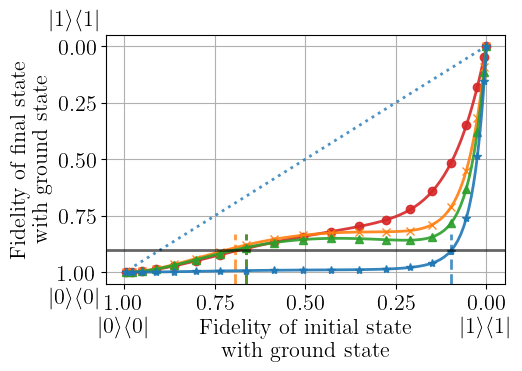

In [21]:
fidelities_original = [fidelity_with_0(x) for x in psis]

from matplotlib import cm
# color = cm.rainbow(np.linspace(1, 0, len(Ms)))
color = ['C3','C1','C2','C0']

max_ext_list = []
fig, ax =  plt.subplots(figsize=(5.5,4))
# ax.plot(np.linspace(0,1,number_steps),res_ITE,label=r"$ITE |{\Psi(\tau)}\rangle$",marker="^")
# ax.plot(np.linspace(0,1,number_steps),res_DBI,label=r"$DBI |{\sigma_k}\rangle$",marker='o')
fidelity = [(1-E)/2 for E in res_init]
ax.plot(fidelities_original,fidelity,label=r"Initial state",linestyle=':', alpha=0.8)
i=0

markers = ['o','x','^','*','P','*','h']

for key,value in dict_fid_RGCI.items():
    max_ext = max_excitation(fidelities_original,np.real(value),target_fidelity)
    if max_ext is not None:
        ax.axvline(x=max_ext,ymax=0.2, color=color[i], alpha=0.8,linestyle='--')
        max_ext_list.append(max_ext)

    ax.plot(fidelities_original,value,label=key,color=color[i],marker=markers[i],markevery=5,markersize=6,alpha=0.9)
    i+=1


plt.gca().invert_xaxis()
plt.gca().invert_yaxis()


# plt.title(r"$k = $" + f" {k}\n")
plt.ylabel('Fidelity of final state\nwith ground state')
plt.xlabel('Fidelity of initial state\nwith ground state')
ax.axhline(y=target_fidelity, color='k', alpha=0.6,label=r'Target F = 'f'{target_fidelity}')
# ax.legend(bbox_to_anchor=(1.05, 1))
if k==1:
        ax.legend()
ax.grid()


_off_set = 0.13

y_min, y_max = ax.get_ylim()
ax.text(0, y_min - _off_set * (y_max - y_min),r'$|1\rangle\langle 1|$', 
        ha='center', va='top')
ax.text(1, y_min - _off_set * (y_max - y_min), r'$|0\rangle\langle 0|$', 
        ha='center', va='top')

# x_min, x_max = ax.get_xlim()
# ax.text(x_min - _off_set * (x_max - x_min), 0, r'$|1\rangle\langle 1|$', 
#         ha='right', va='center')
# ax.text(x_min - _off_set * (x_max - x_min), 1, r'$|0\rangle\langle 0|$', 
#         ha='right', va='center')

x_min, x_max = ax.get_xlim()
        
# Add text labels below y=0 and above y=1
ax.text(1 + _off_set*0.5, 0 + _off_set*0.8 * (ax.get_ylim()[1] - ax.get_ylim()[0]), r'$|1\rangle\langle 1|$', 
        ha='right', va='center')
ax.text(1 + _off_set*0.5, 1 - _off_set*0.8 * (ax.get_ylim()[1] - ax.get_ylim()[0]), r'$|0\rangle\langle 0|$', 
        ha='right', va='center')

plt.savefig(f'plots/QITE_DME_k_{k}_M_fidelity_final_vs_original.pdf')

plt.tight_layout()

for M, max_val in zip(Ms, max_ext_list):
    print((M,np.round(max_val,2)))

